In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt


from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.preprocessing import StandardScaler

In [3]:
data = {
    'Size' : [500 , 700, 900 , 1100 , 1300, 1500, 1700, 1900],
    'Bedrooms' : [1, 2, 2,3,3,3, 4, 4],
    'Age' : [10 , 8, 5, 4, 2, 3,1 ,2],
    'Distance' : [15, 12, 10, 8,7, 6, 4, 3],
    'Price' : [25, 35, 45, 55,65, 70, 85, 90]
}
df = pd.DataFrame(data)
print(df)

   Size  Bedrooms  Age  Distance  Price
0   500         1   10        15     25
1   700         2    8        12     35
2   900         2    5        10     45
3  1100         3    4         8     55
4  1300         3    2         7     65
5  1500         3    3         6     70
6  1700         4    1         4     85
7  1900         4    2         3     90


In [4]:
X = df.drop('Price', axis=1)
y=df['Price']

In [5]:
X

,Size,Bedrooms,Age,Distance
0,500,1,10,15
1,700,2,8,12
2,900,2,5,10
3,1100,3,4,8
4,1300,3,2,7
5,1500,3,3,6
6,1700,4,1,4
7,1900,4,2,3


In [6]:
y

0    25
1    35
2    45
3    55
4    65
5    70
6    85
7    90
Name: Price, dtype: int64

In [8]:
scaler = StandardScaler()
X_Scaled = scaler.fit_transform(X)
X_Scaled

array([[-1.52752523, -1.80739223,  1.9032972 ,  1.81428259],
       [-1.09108945, -0.77459667,  1.22656931,  1.02259564],
       [-0.65465367, -0.77459667,  0.21147747,  0.49480434],
       [-0.21821789,  0.25819889, -0.12688648, -0.03298696],
       [ 0.21821789,  0.25819889, -0.80361438, -0.29688261],
       [ 0.65465367,  0.25819889, -0.46525043, -0.56077826],
       [ 1.09108945,  1.29099445, -1.14197832, -1.08856956],
       [ 1.52752523,  1.29099445, -0.80361438, -1.35246521]])

In [9]:
lr = LinearRegression()
lr.fit(X_Scaled , y)
print("Linear Regression Coefficients : ", lr.coef_)

Linear Regression Coefficients :  [22.54261333  5.78002267 -4.43871503 10.73416565]


In [17]:
ridge = Ridge(alpha=1.0) #Creates a ridge model with Regularization strength 1
ridge.fit(X_Scaled, y)

print("Ridge Coefficients : ", ridge.coef_)

Ridge Coefficients :  [ 8.09669482  4.65220092 -2.87707444 -5.43036908]


In [13]:
lasso = Lasso(alpha=1.0)
lasso.fit(X_Scaled , y)
print("Lasso Coefficients : ", lasso.coef_)

Lasso Coefficients :  [16.71509076  2.7263582  -1.33933083 -0.        ]


In [14]:
comparison = pd.DataFrame({
    'Feature': X.columns,
    'Linear': lr.coef_,
    'Ridge': ridge.coef_,
    'Lasso': lasso.coef_
})

print(comparison)

    Feature     Linear     Ridge      Lasso
0      Size  22.542613  8.096695  16.715091
1  Bedrooms   5.780023  4.652201   2.726358
2       Age  -4.438715 -2.877074  -1.339331
3  Distance  10.734166 -5.430369  -0.000000


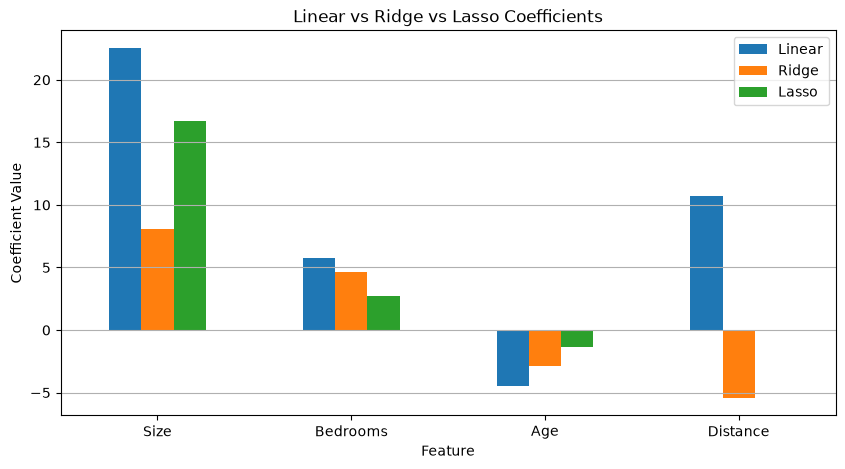

In [15]:
comparison.set_index('Feature').plot(
    kind='bar',
    figsize=(10, 5)
)

plt.title('Linear vs Ridge vs Lasso Coefficients')
plt.ylabel('Coefficient Value')
plt.xticks(rotation=0)
plt.grid(axis='y')
plt.show()

In [18]:
new_house = pd.DataFrame({
    'Size' : [1600],
    'Bedrooms': [4],
    'Age': [2],
    'Distance': [5]
})
new_house_scaled = scaler.transform(new_house)
prediction = ridge.predict(new_house_scaled)
print("Predicted House Price : ", prediction[0], "Lakhs")

Predicted House Price :  78.61368226413703 Lakhs
